# QAOA and VQE: two inspectable hybrid workflows

This notebook executes a four-vertex MaxCut example and a two-qubit variational energy example using **Qiskit core**. Their small classical reference answers are computed independently. It reproduces exact-statevector optimization, then performs a separate finite-shot experiment at parameters selected by the first prescribed initialization.

Save the public `optimization.py` download beside this notebook to run it independently, or run from the source checkout. Use the published Python 3.12 environment lock. No live widgets or public kernel service are required to serve the saved outputs.

The original QAOA algorithm is due to Farhi, Goldstone and Gutmann (2014), arXiv:1411.4028 {cite:p}`opt_qaoa2014`; the original VQE demonstration is due to Peruzzo et al. (2014), DOI:10.1038/ncomms5213 {cite:p}`opt_vqe2014`. The chapter bibliography provides full citations and the exact Qiskit and NumPy releases {cite:p}`opt_qiskit262,opt_numpy254`. Our circuits, numerical checks and figures are original. Qiskit core is Apache-2.0; NumPy is BSD-3-Clause; Matplotlib is based on the PSF license; the downloaded implementation is MIT.

These are ideal, bounded examples. Their optimization behavior is measured on these instances; it does not establish approximation guarantees, hardware performance or convergence on larger problems.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import importlib.util
import platform
import sys

# Load one explicit source file. Never silently resolve an editable installation.
working_directory = Path.cwd().resolve()
candidates = [
    ("checkout", working_directory / "src/openquantum/optimization.py"),
    ("checkout", working_directory.parent / "src/openquantum/optimization.py"),
    ("standalone download", working_directory / "optimization.py"),
    ("standalone download", working_directory / "notebooks/optimization.py"),
]
selected = next(((kind, path.resolve()) for kind, path in candidates if path.is_file()), None)
if selected is None:
    raise FileNotFoundError("Save optimization.py beside the notebook, or run in its source checkout.")
source_kind, imported_module_source = selected
spec = importlib.util.spec_from_file_location("optimization_notebook_source", imported_module_source)
opt = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = opt
spec.loader.exec_module(opt)
assert Path(opt.__file__).resolve() == imported_module_source
# imported_module_source records the actual path in the kernel; saved output omits it.
print({
    "source": source_kind,
    "implementation_sha256": hashlib.sha256(imported_module_source.read_bytes()).hexdigest(),
    "python": platform.python_version(),
    "packages": {name: importlib.metadata.version(name) for name in ("qiskit", "numpy", "matplotlib")},
})

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from html import escape
import os
from qiskit import qasm3
from qiskit.quantum_info import Statevector
from time import perf_counter


def display_result_table(rows):
    # Plain HTML tables render statically in the pinned MyST theme.
    table_rows = [row for row in rows if row.startswith("|")]
    header = [cell.strip() for cell in table_rows[0].strip("|").split("|")]
    body = [[cell.strip() for cell in row.strip("|").split("|")]
            for row in table_rows[2:]]
    html = "<table><thead><tr>" + "".join("<th>"+escape(cell)+"</th>" for cell in header)
    html += "</tr></thead><tbody>"
    for row in body:
        html += "<tr>"+"".join("<td>"+escape(cell)+"</td>" for cell in row)+"</tr>"
    html += "</tbody></table>"
    html += "".join("<p>"+escape(row)+"</p>" for row in rows if row and not row.startswith("|"))
    if os.environ.get("OPENQUANTUM_STATIC_BUILD") == "1":
        # Static theme does not render arbitrary MIME HTML/Markdown tables.
        # Main chapter uses the native MyST generated summary; this output
        # keeps the rendered notebook readable with no client MIME renderer.
        print("\n".join(rows))
    else:
        display(HTML(html))


{'source': 'checkout', 'implementation_sha256': 'a617b5e8d43b648427e5ceaa5e35d3f50ea14c02464465084f23f457ffb5855d', 'python': '3.12.14', 'packages': {'qiskit': '2.6.2', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}}


## Explicit tasks and independent classical references

The MaxCut graph is the cycle with vertices $0,1,2,3$ and edges $(0,1),(1,2),(2,3),(0,3)$. The objective is the number of cut edges,

$$C(z)=\sum_{(u,v)}\frac{1-Z_uZ_v}{2}.$$

Qiskit wire `q[0]` is the least significant bit. Displayed bitstrings read `q[3] q[2] q[1] q[0]`. We enumerate all 16 assignments before using a quantum circuit.

For VQE the input is the explicit Hamiltonian

$$H=-Z_0-Z_1+\tfrac12X_0X_1.$$

The independent NumPy matrix uses basis order $|00\rangle,|01\rangle,|10\rangle,|11\rangle$. Exact diagonalization is a reference calculation on this four-dimensional input.

In [2]:
edges = tuple(opt.CYCLE_EDGES)
n_qubits = 4
cut_values = np.array([
    sum(((assignment >> u) & 1) != ((assignment >> v) & 1) for u, v in edges)
    for assignment in range(2**n_qubits)
], dtype=float)
np.testing.assert_array_equal(opt.maxcut_values(n_qubits, edges), cut_values)
classical_cut_optimum = float(cut_values.max())
classical_best_strings = [f"{i:04b}" for i in np.flatnonzero(cut_values == classical_cut_optimum)]

I = np.eye(2)
X = np.array([[0., 1.], [1., 0.]])
Z = np.diag([1., -1.])
independent_hamiltonian = -np.kron(I, Z) - np.kron(Z, I) + .5*np.kron(X, X)
np.testing.assert_allclose(opt.vqe_hamiltonian(), independent_hamiltonian, atol=1e-14, rtol=0)
exact_eigenvalues = np.linalg.eigvalsh(independent_hamiltonian)
exact_ground_energy = float(exact_eigenvalues[0])
np.testing.assert_allclose(exact_ground_energy, -np.sqrt(4.25), atol=1e-14, rtol=0)
print({"MaxCut optimum": classical_cut_optimum, "optimal bitstrings": classical_best_strings,
       "Hamiltonian eigenvalues": exact_eigenvalues.tolist()})

{'MaxCut optimum': 4.0, 'optimal bitstrings': ['0101', '1010'], 'Hamiltonian eigenvalues': [-2.0615528128088303, -0.5, 0.5, 2.0615528128088303]}


## Reproduce exact-statevector optimization

Depth-one QAOA prepares $|+\rangle^{\otimes4}$, applies $e^{-i\gamma C}$, then $e^{-i\beta\sum_jX_j}$. Each cost edge is implemented by `CX; RZ(-gamma); CX`; its omitted global phase does not affect the output. The mixer uses `RX(2 beta)`. The minimizer receives $-\langle C\rangle$.

The VQE circuit prepares $R_Y(\theta)$ on qubit 0 and then `CX(0,1)`. It has state $\cos(\theta/2)|00\rangle+\sin(\theta/2)|11\rangle$ and minimizes $\langle H\rangle$.

Every objective evaluation below checks the independently derived formulas

$$\langle C\rangle=2+\sin(4\beta)\sin(2\gamma),\qquad
E(\theta)=-2\cos\theta+\tfrac12\sin\theta.$$

The deterministic coordinate polling optimizer starts with step 0.4 radians, evaluates both directions of each coordinate in a fixed order, accepts an improvement greater than $10^{-12}$, and halves its step when no candidate improves the current value. It stops when the step is below $10^{-6}$ radians or after 128 iterations. Angles are periodic modulo $2\pi$. These stopping rules are empirical search settings, not a bound on the objective gap.

All three initializations are fixed below. The first run is selected for plots and sampled readout in advance. The complete canonical traces, including every trial objective and measured optimizer time, are in the downloadable `runs.json` and `evaluations.csv`. This notebook executes new reproductions; its measured times can differ from those artifacts.

In [3]:
def checked_qaoa_objective(parameters):
    gamma, beta = parameters
    observed = opt.qaoa_expectation(n_qubits, edges, [gamma], [beta])
    predicted = 2 + np.sin(4*beta)*np.sin(2*gamma)
    np.testing.assert_allclose(observed, predicted, atol=2e-12, rtol=0)
    return -observed


def checked_vqe_objective(parameters):
    theta = parameters[0]
    observed = opt.vqe_expectation(theta)
    predicted = -2*np.cos(theta) + .5*np.sin(theta)
    np.testing.assert_allclose(observed, predicted, atol=2e-12, rtol=0)
    return observed


search_settings = dict(initial_step=.4, step_tolerance=1e-6,
                       improvement_tolerance=1e-12, max_iterations=128)
qaoa_initializations = [(0.2, 0.1), (0.6, 0.4), (-0.3, 0.25)]
vqe_initializations = [(0.6,), (-1.1,), (2.2,)]
qaoa_runs, vqe_runs = [], []
reproduction_seconds = {"qaoa": [], "vqe": []}
for name, objective, starts, destination in (
    ("qaoa", checked_qaoa_objective, qaoa_initializations, qaoa_runs),
    ("vqe", checked_vqe_objective, vqe_initializations, vqe_runs),
):
    for initial in starts:
        started = perf_counter()
        result = opt.pattern_search(objective, initial, objective_method="exact_statevector", **search_settings)
        reproduction_seconds[name].append(perf_counter() - started)
        destination.append(result)

qaoa_result, vqe_result = qaoa_runs[0], vqe_runs[0]
gamma, beta = qaoa_result["parameters"]
theta = vqe_result["parameters"][0]
qaoa_expected_cut = -qaoa_result["value"]
vqe_energy = vqe_result["value"]
assert abs(qaoa_expected_cut - 3) < 1e-8
assert abs(vqe_energy - exact_ground_energy) < 1e-8
print("All objective evaluations passed their independent analytic checks.")

All objective evaluations passed their independent analytic checks.


In [4]:
rows = ["| Workflow / fixed start | Final exact objective | Evaluations | Iterations | Stop | Reproduction seconds |",
        "|---|---:|---:|---:|---|---:|"]
for name, starts, runs in (("QAOA expected cut", qaoa_initializations, qaoa_runs),
                          ("VQE energy", vqe_initializations, vqe_runs)):
    for index, (initial, result) in enumerate(zip(starts, runs)):
        objective = -result["value"] if name.startswith("QAOA") else result["value"]
        seconds = reproduction_seconds["qaoa" if name.startswith("QAOA") else "vqe"][index]
        rows.append(f"| {name}, {initial} | {objective:.10f} | {len(result['evaluations'])} | "
                    f"{len(result['iterations'])} | {result['stop_reason']} | {seconds:.4f} |")
rows += ["", f"The classical cut optimum is {classical_cut_optimum:g}; the first QAOA run's exact expected-cut ratio is "
         f"{qaoa_expected_cut/classical_cut_optimum:.10f}. The first VQE run's gap to the exact ground energy is "
         f"{vqe_energy-exact_ground_energy:.3g}. These are exact-statevector results on the specified small inputs."]
display_result_table(rows)

| Workflow / fixed start | Final exact objective | Evaluations | Iterations | Stop | Reproduction seconds |
|---|---:|---:|---:|---|---:|
| QAOA expected cut, (0.2, 0.1) | 3.0000000000 | 169 | 42 | step_tolerance | 0.1094 |
| QAOA expected cut, (0.6, 0.4) | 3.0000000000 | 153 | 38 | step_tolerance | 0.0932 |
| QAOA expected cut, (-0.3, 0.25) | 3.0000000000 | 173 | 43 | step_tolerance | 0.1087 |
| VQE energy, (0.6,) | -2.0615528128 | 63 | 31 | step_tolerance | 0.0148 |
| VQE energy, (-1.1,) | -2.0615528128 | 65 | 32 | step_tolerance | 0.0152 |
| VQE energy, (2.2,) | -2.0615528128 | 71 | 35 | step_tolerance | 0.0160 |

The classical cut optimum is 4; the first QAOA run's exact expected-cut ratio is 0.7500000000. The first VQE run's gap to the exact ground energy is 1.13e-13. These are exact-statevector results on the specified small inputs.


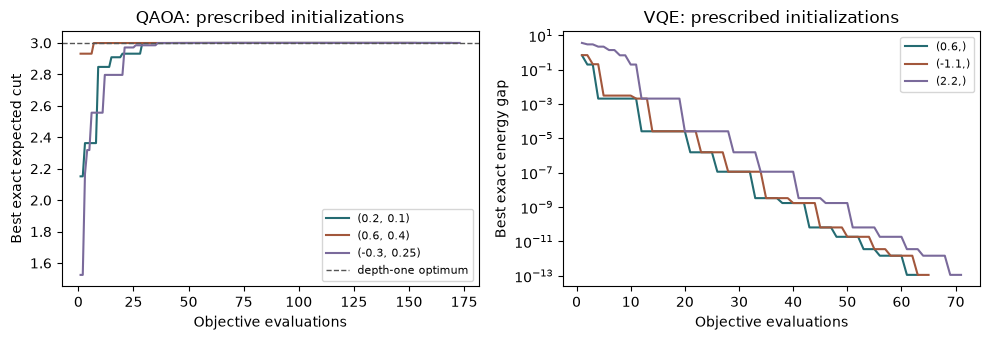

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
colors = ["#246b72", "#a2573c", "#7a6a9b"]
for run, color, initial in zip(qaoa_runs, colors, qaoa_initializations):
    values = np.array([entry["value"] for entry in run["evaluations"]])
    axes[0].plot(np.arange(1, len(values)+1), -np.minimum.accumulate(values),
                 color=color, label=str(initial))
axes[0].axhline(3, color="#555555", ls="--", lw=1, label="depth-one optimum")
axes[0].set(xlabel="Objective evaluations", ylabel="Best exact expected cut",
            title="QAOA: prescribed initializations")
axes[0].legend(fontsize=8)
for run, color, initial in zip(vqe_runs, colors, vqe_initializations):
    values = np.array([entry["value"] for entry in run["evaluations"]])
    gaps = np.maximum(np.minimum.accumulate(values)-exact_ground_energy, 1e-14)
    axes[1].semilogy(np.arange(1, len(values)+1), gaps, color=color, label=str(initial))
axes[1].set(xlabel="Objective evaluations", ylabel="Best exact energy gap",
            title="VQE: prescribed initializations")
axes[1].legend(fontsize=8)
figure.tight_layout()
plt.show()
plt.close(figure)

## Inspect the circuits at the selected parameters

The figures show actual circuits generated by the implementation. Their rotations remain unsynthesized; a drawn circuit is not a fault-tolerant physical estimate. Measurements are added separately for the readout procedure below.

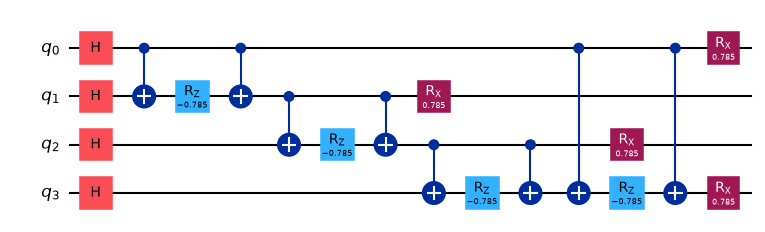

In [6]:
qaoa_circuit = opt.build_qaoa_circuit(n_qubits, edges, [gamma], [beta])
figure = qaoa_circuit.draw(output="mpl", fold=40, scale=.75)
display(figure)
plt.close(figure)

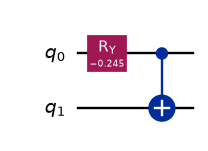

In [7]:
vqe_circuit = opt.build_vqe_circuit(theta)
figure = vqe_circuit.draw(output="mpl", fold=40, scale=.85)
display(figure)
plt.close(figure)

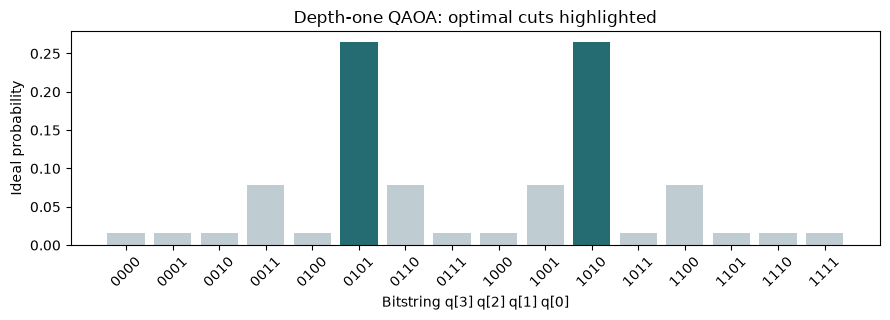

{'expected cut': 2.9999999999972777, 'classical optimum': 4.0, 'probability of an optimal cut in one ideal readout': 0.5312497938662445, 'probability in seven independent ideal readouts': 0.9950273224108687}


In [8]:
qaoa_probabilities = Statevector.from_instruction(qaoa_circuit).probabilities()
np.testing.assert_allclose(np.dot(qaoa_probabilities, cut_values), qaoa_expected_cut,
                           atol=1e-12, rtol=0)
qaoa_optimal_probability = float(qaoa_probabilities[cut_values == classical_cut_optimum].sum())
analytic_optimum_probabilities = Statevector.from_instruction(
    opt.build_qaoa_circuit(n_qubits, edges, [np.pi/4], [np.pi/8])).probabilities()
np.testing.assert_allclose(analytic_optimum_probabilities[cut_values == classical_cut_optimum].sum(),
                           17/32, atol=1e-12, rtol=0)
# Polling stops by angle step; the readout probability may differ linearly in angle error.
np.testing.assert_allclose(qaoa_optimal_probability, 17/32, atol=1e-6, rtol=0)
figure, axis = plt.subplots(figsize=(9, 3.3))
indices = np.arange(len(qaoa_probabilities))
axis.bar(indices, qaoa_probabilities,
         color=["#246b72" if value == classical_cut_optimum else "#bfccd1" for value in cut_values])
axis.set_xticks(indices, [f"{i:04b}" for i in indices], rotation=45)
axis.set(xlabel="Bitstring q[3] q[2] q[1] q[0]", ylabel="Ideal probability",
         title="Depth-one QAOA: optimal cuts highlighted")
figure.tight_layout()
plt.show()
plt.close(figure)
print({"expected cut": qaoa_expected_cut, "classical optimum": classical_cut_optimum,
       "probability of an optimal cut in one ideal readout": qaoa_optimal_probability,
       "probability in seven independent ideal readouts": 1-(1-qaoa_optimal_probability)**7})

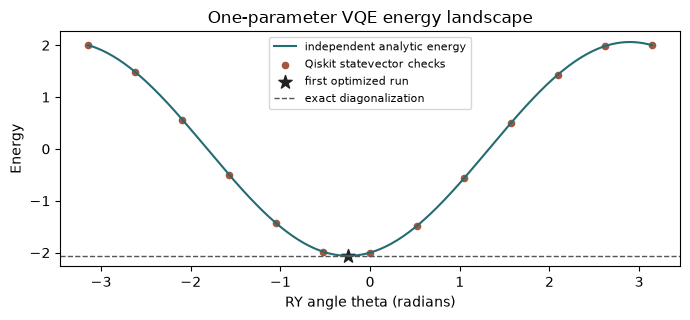

In [9]:
angle_grid = np.linspace(-np.pi, np.pi, 300)
analytic_energies = -2*np.cos(angle_grid)+.5*np.sin(angle_grid)
check_angles = np.linspace(-np.pi, np.pi, 13)
checked_energies = np.array([opt.vqe_expectation(angle) for angle in check_angles])
np.testing.assert_allclose(checked_energies, -2*np.cos(check_angles)+.5*np.sin(check_angles),
                           atol=1e-12, rtol=0)
figure, axis = plt.subplots(figsize=(7, 3.3))
axis.plot(angle_grid, analytic_energies, color="#246b72", label="independent analytic energy")
axis.scatter(check_angles, checked_energies, color="#a2573c", s=20, label="Qiskit statevector checks")
axis.scatter([theta], [vqe_energy], color="#222222", marker="*", s=100, label="first optimized run")
axis.axhline(exact_ground_energy, color="#555555", ls="--", lw=1, label="exact diagonalization")
axis.set(xlabel="RY angle theta (radians)", ylabel="Energy", title="One-parameter VQE energy landscape")
axis.legend(fontsize=8)
figure.tight_layout()
plt.show()
plt.close(figure)

## Separate finite-shot readout

Optimization above uses **zero shots**: each objective is evaluated by an ideal statevector. The following held-out sampling experiments evaluate the first optimized parameters with seeds 7, 19 and 41. They do not train a noisy or sampled optimizer.

For QAOA, a single all-Z measurement of all four qubits supplies every edge contribution and a candidate cut. Each seeded experiment uses 2,048 independently simulated shots.

For VQE, measure both qubits in Z to estimate the **joint observable** $-Z_0-Z_1$, preserving the covariance of its terms. In a separate group, apply H to both qubits and measure Z to estimate $\tfrac12X_0X_1$. Each group uses 2,048 shots per seed. Group sample means are added, and their sample variances determine a descriptive estimated standard error. This standard error is not a confidence or device-error guarantee.

Sampling uses the implementation's NumPy `Generator(PCG64)` multinomial sampler from the actual circuit probabilities. The QAOA and VQE Z groups use the listed seed; the independent VQE X stream uses that seed plus 1,000,003. The notebook recomputes every sampled mean and group standard error directly from the returned counts. State preparation and the change of measurement basis are present in the generated circuits. Device noise, mitigation, fault-tolerant synthesis and hardware execution time are excluded.

In [10]:
shots_per_group = 2048
sampling_seeds = (7, 19, 41)
z_group_probabilities = Statevector.from_instruction(opt.build_vqe_circuit(theta, basis="z")).probabilities()
x_group_probabilities = Statevector.from_instruction(opt.build_vqe_circuit(theta, basis="x")).probabilities()
indices_two = np.arange(4)
z0 = 1-2*(indices_two & 1)
z1 = 1-2*((indices_two >> 1) & 1)
z_group_values = -z0-z1
x_group_values = .5*z0*z1
np.testing.assert_allclose(np.dot(z_group_probabilities, z_group_values)
                           + np.dot(x_group_probabilities, x_group_values),
                           vqe_energy, atol=1e-12, rtol=0)


def observed_mean_and_standard_error(counts_by_bitstring, values):
    counts = np.array([counts_by_bitstring.get(f"{index:0{int(np.log2(len(values)))}b}", 0)
                       for index in range(len(values))])
    count = int(np.sum(counts))
    mean = float(np.dot(counts, values)/count)
    variance = float(np.dot(counts, (values-mean)**2)/(count-1))
    return mean, np.sqrt(variance/count)


sample_records = []
for seed in sampling_seeds:
    q_readout = opt.sample_qaoa(gamma, beta, shots=shots_per_group, seed=seed)
    v_readout = opt.sample_vqe(theta, shots=shots_per_group, seed=seed)
    q_mean, q_se = observed_mean_and_standard_error(q_readout["counts"], cut_values)
    z_group, x_group = v_readout["groups"]
    z_mean, z_se = observed_mean_and_standard_error(z_group["counts"], z_group_values)
    x_mean, x_se = observed_mean_and_standard_error(x_group["counts"], x_group_values)
    np.testing.assert_allclose([q_mean, q_se],
                               [q_readout["estimate"], q_readout["estimated_standard_error"]],
                               atol=1e-12, rtol=0)
    np.testing.assert_allclose([z_mean+x_mean, np.hypot(z_se, x_se)],
                               [v_readout["estimate"], v_readout["estimated_standard_error"]],
                               atol=1e-12, rtol=0)
    assert sum(q_readout["counts"].values()) == shots_per_group
    assert sum(z_group["counts"].values()) == shots_per_group
    assert sum(x_group["counts"].values()) == shots_per_group
    sample_records.append({"seed": seed, "qaoa": q_readout, "vqe": v_readout})
rows = ["| Seed | Sampled mean cut | Cut SE | Optimal-cut fraction | Sampled VQE energy | Energy SE |",
        "|---:|---:|---:|---:|---:|---:|"]
for record in sample_records:
    q, v = record["qaoa"], record["vqe"]
    rows.append(f"| {record['seed']} | {q['estimate']:.6f} | {q['estimated_standard_error']:.6f} | "
                f"{q['optimal_cut_sample_fraction']:.6f} | {v['estimate']:.6f} | {v['estimated_standard_error']:.6f} |")
display_result_table(rows)
print({"exact-optimization shots": 0, "sampled QAOA shots across three seeds": 3*shots_per_group,
       "sampled VQE shots across three seeds and two groups": 3*2*shots_per_group,
       "combined sampled shots": 3*3*shots_per_group})

| Seed | Sampled mean cut | Cut SE | Optimal-cut fraction | Sampled VQE energy | Energy SE |
|---:|---:|---:|---:|---:|---:|
| 7 | 3.028320 | 0.023998 | 0.536621 | -2.101562 | 0.013327 |
| 19 | 2.998047 | 0.024865 | 0.532227 | -2.066895 | 0.015636 |
| 41 | 2.976562 | 0.024860 | 0.521484 | -2.041016 | 0.016169 |
{'exact-optimization shots': 0, 'sampled QAOA shots across three seeds': 6144, 'sampled VQE shots across three seeds and two groups': 12288, 'combined sampled shots': 18432}


## Circuit generation is separate from bounded simulation

The next example materializes a 20-qubit, three-layer QAOA cycle without allocating its exponentially large statevector. The implementation validates circuit-size limits separately from its defaults of 12 qubits for exact simulation and 16 qubits for exhaustive enumeration (hard limits: 16 and 20 respectively). Larger circuit construction is still bounded work; none of these numbers establishes a scalable optimizer.

The OpenQASM preview is produced from a real circuit with preparation, cost phases, mixing and final measurement. Arbitrary rotations still require an explicit synthesis-error allocation before any physical estimate.

In [11]:
larger_n = 20
larger_edges = [(index, index+1) for index in range(larger_n-1)] + [(0, larger_n-1)]
larger = opt.build_qaoa_circuit(larger_n, larger_edges, [.2, .3, .4], [.1, .2, .3], measure=True)
compiled_larger = opt.compile_rotation_basis(larger)
qasm_export = qasm3.dumps(compiled_larger)
print({"qubits": compiled_larger.num_qubits, "depth": compiled_larger.depth(),
       "counts": dict(compiled_larger.count_ops()), "export characters": len(qasm_export),
       "statevector simulation performed": False, "rotation synthesis performed": False})
print("\n".join(qasm_export.splitlines()[:6]))

{'qubits': 20, 'depth': 185, 'counts': {'cx': 120, 'rz': 60, 'rx': 60, 'h': 20, 'measure': 20, 'barrier': 1}, 'export characters': 4596, 'statevector simulation performed': False, 'rotation synthesis performed': False}
OPENQASM 3.0;
include "stdgates.inc";
bit[20] meas;
qubit[20] q;
h q[0];
h q[1];


## What the workload records mean

A complete hybrid run includes the classical input, every accepted and rejected optimizer trial, circuit preparation and evaluation, optimizer control time, and final sampled readout. A statevector objective is a classical numerical calculation and has no measured quantum shot budget. Converting this search into a hardware optimizer would require a new shot allocation and stopping analysis; its cost is not silently inferred from one ansatz circuit.

The generated resource ledger records both the full exact-simulation workload and the separate sampled workload, including measurement groups, repetitions and logical circuit counts. It leaves arbitrary-rotation synthesis and physical resources explicitly pending. The existing Grover surface-code baseline is unchanged.

For the complete canonical artifacts, download `runs.json`, `evaluations.csv`, `logical-resources.json`, the measured `qaoa.qasm`, `vqe-z.qasm`, `vqe-x.qasm`, and the implementation from the optimization chapter. Their reported optimizer times are measurements of that generation run, not portable performance claims. The notebook's regenerated traces and `sample_records` remain available in its kernel for inspection.